<a href="https://colab.research.google.com/github/sagarsinha-code/LeetCode/blob/main/DNN_Assignment2_problem1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PHASE 1: ENVIRONMENT
{
  "python": "3.13.18",
  "torch": "2.14.1+cpu",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "matplotlib": "3.10.0",
  "scikit_learn": "1.6.1",
  "cuda_available": "False",
  "configured_environment": "Google Colab T4"
}

PHASE 1: UCI HAR
Using existing file: DNN_Assignment/data/har/har.zip
HAR dataset root: DNN_Assignment/data/har/UCI HAR Dataset
HAR archive SHA256: c00b803081a5c797cd5e4b83700a9810b38d53d9d84e01917e090e1fdbc81031
HAR train: (7352, 128, 9) (7352,)
HAR test:  (2947, 128, 9) (2947,)
Train subjects: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Test subjects:  [2, 4, 9, 10, 12, 13, 18, 20, 24]
Seed 42: validation subjects = [3, 16, 22, 23], train=(5952, 128, 9), val=(1400, 128, 9)
Seed 123: validation subjects = [1, 3, 19, 21], train=(5896, 128, 9), val=(1456, 128, 9)
Seed 2026: validation subjects = [1, 6, 22, 25], train=(5950, 128, 9), val=(1402, 128, 9)


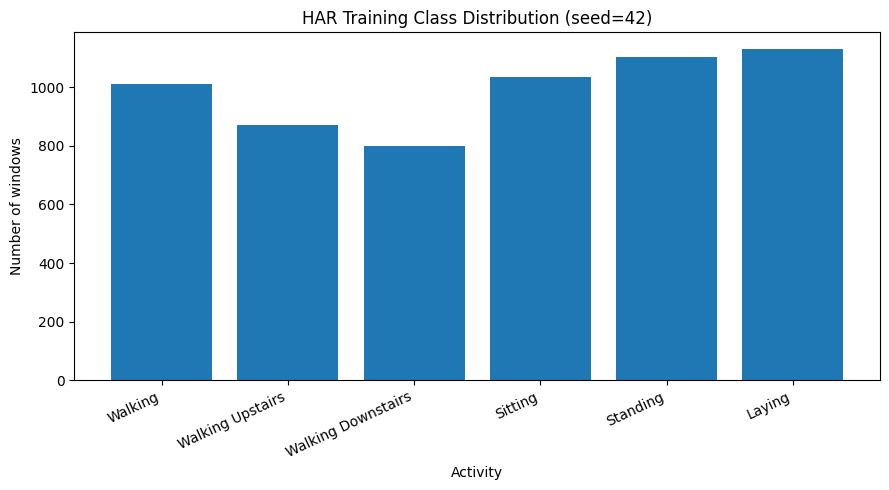

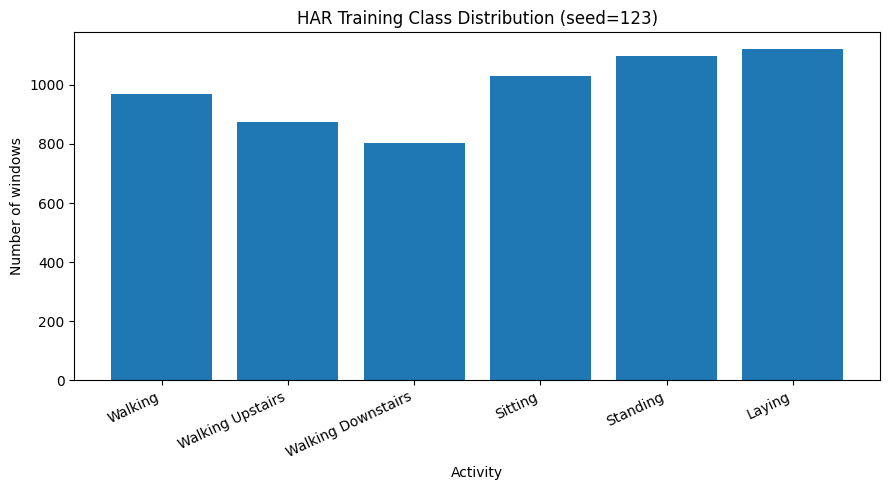

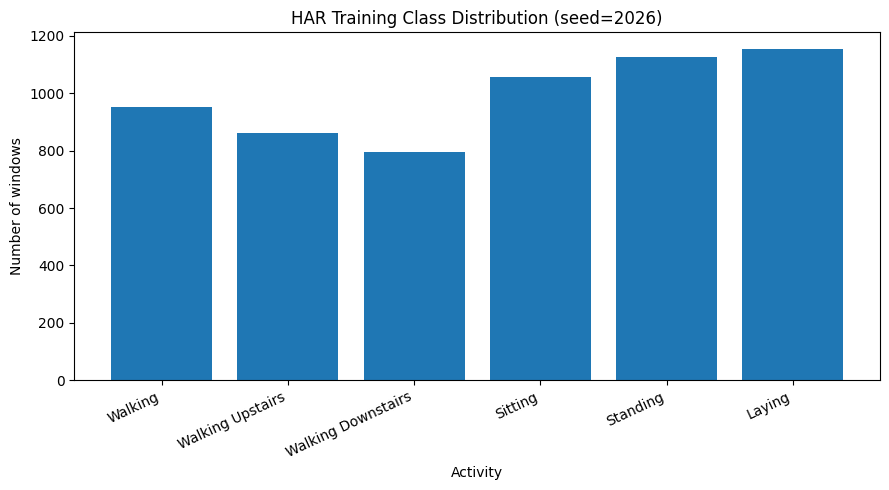


PHASE 1: ADDING PROBLEM
Adding T=50: train=(10000, 50, 2), val=(1000, 50, 2), test=(1000, 50, 2), constant-1 test MSE=0.17539
Adding T=100: train=(10000, 100, 2), val=(1000, 100, 2), test=(1000, 100, 2), constant-1 test MSE=0.16971
Adding T=200: train=(10000, 200, 2), val=(1000, 200, 2), test=(1000, 200, 2), constant-1 test MSE=0.16794
Adding T=400: train=(10000, 400, 2), val=(1000, 400, 2), test=(1000, 400, 2), constant-1 test MSE=0.15272

PHASE 1: TINY SHAKESPEARE
Saved DNN_Assignment/data/shakespeare/input.txt (1,115,394 bytes)
Tiny Shakespeare characters: 1115394
Tiny Shakespeare SHA256: 86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed
Vocabulary size: 65
Train characters: 1003854
Validation characters: 111540
Sequential split: 1003854 / 1115394
Saved metadata: DNN_Assignment/outputs/phase1_metadata.json

PHASE 1 COMPLETE
Project directory: /content/DNN_Assignment
Next: implement and validate custom recurrent cells.


In [2]:
# ============================================================
# DNN Programming Assignment - Phase 1
# Environment + UCI HAR + Adding Problem + Tiny Shakespeare
# Target: Google Colab T4, Python 3.10+, PyTorch 2.x
#
# Run in Colab:
#   1. Runtime -> Change runtime type -> T4 GPU
#   2. Run the dependency/version cell in the notebook (below).
#   3. Save this file in /content or Drive and run:
#        %run /content/phase1_dnn.py
#
# This file prepares data only. It does NOT implement or train
# any RNN/LSTM/GRU/Transformer model.
# ============================================================

# -------------------------
# CELL 0: Colab setup
# -------------------------
# In a fresh Colab notebook, run this as a separate cell BEFORE
# running this script. Do not reinstall PyTorch unnecessarily.
#
# %pip install -q numpy pandas matplotlib scikit-learn
#
# To mount Drive for persistence (optional):
# from google.colab import drive
# drive.mount("/content/drive")

# -------------------------
# CELL 1: Imports/config
# -------------------------
import os
import sys
import json
import random
import hashlib
import urllib.request
import zipfile
from pathlib import Path
from typing import Dict, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import torch
from torch.utils.data import Dataset, DataLoader

if sys.version_info < (3, 10):
    raise RuntimeError("Python 3.10 or later is required.")
if int(torch.__version__.split(".")[0]) < 2:
    raise RuntimeError("PyTorch 2.x or later is required.")

CONFIG = {
    "hidden_size_h": 96,
    "transformer_width_d": 96,
    "attention_heads": 4,
    "seeds": [42, 123, 2026],
    "environment": "Google Colab T4",
}

assert CONFIG["transformer_width_d"] % CONFIG["attention_heads"] == 0
HEAD_DIM = CONFIG["transformer_width_d"] // CONFIG["attention_heads"]

# Relative project paths. In Colab, the default root is /content.
PROJECT_DIR = Path("DNN_Assignment")
DATA_DIR = PROJECT_DIR / "data"
HAR_DIR = DATA_DIR / "har"
SHAKESPEARE_DIR = DATA_DIR / "shakespeare"
P1_FIGURES_DIR = PROJECT_DIR / "problem1" / "figures"
P2_FIGURES_DIR = PROJECT_DIR / "problem2" / "figures"
OUTPUT_DIR = PROJECT_DIR / "outputs"

for directory in [
    HAR_DIR, SHAKESPEARE_DIR,
    P1_FIGURES_DIR, P2_FIGURES_DIR, OUTPUT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# Assignment-specified source URLs.
HAR_URL = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)
SHAKESPEARE_URL = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/"
    "master/data/tinyshakespeare/input.txt"
)

CHANNELS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
]
ACTIVITIES = [
    "Walking", "Walking Upstairs", "Walking Downstairs",
    "Sitting", "Standing", "Laying",
]


# -------------------------
# CELL 2: Environment checks
# -------------------------
def print_environment() -> Dict[str, str]:
    """Print and return the runtime/software versions."""
    info = {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
        "scikit_learn": sklearn.__version__,
        "cuda_available": str(torch.cuda.is_available()),
        "configured_environment": CONFIG["environment"],
    }

    print(json.dumps(info, indent=2))
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("CUDA runtime:", torch.version.cuda)
    else:
        print(
            "WARNING: CUDA is unavailable. In Colab select "
            "Runtime > Change runtime type > T4 GPU."
        )
    return info


def set_seed(seed: int) -> None:
    """
    Seed Python, NumPy and PyTorch.
    Small nondeterministic differences can still occur on GPU.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Prefer reproducibility over speed for this coursework.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def write_environment_files() -> None:
    """Write chosen configuration and exact installed versions."""
    env = print_environment()
    env["configuration"] = CONFIG
    env["head_dimension"] = HEAD_DIM

    with open(PROJECT_DIR / "phase1_environment.json", "w") as f:
        json.dump(env, f, indent=2)

    requirements = [
        f"numpy=={np.__version__}",
        f"pandas=={pd.__version__}",
        f"matplotlib=={matplotlib.__version__}",
        f"scikit-learn=={sklearn.__version__}",
        f"torch=={torch.__version__.split('+')[0]}",
    ]
    (PROJECT_DIR / "phase1_requirements.txt").write_text(
        "\n".join(requirements) + "\n",
        encoding="utf-8",
    )


# -------------------------
# CELL 3: Download helpers
# -------------------------
def download_file(url: str, destination: Path,
                  chunk_size: int = 1024 * 1024) -> Path:
    """Download URL to destination, reusing a non-empty existing file."""
    destination.parent.mkdir(parents=True, exist_ok=True)

    if destination.exists() and destination.stat().st_size > 0:
        print(f"Using existing file: {destination}")
        return destination

    print(f"Downloading {url}")
    request = urllib.request.Request(
        url, headers={"User-Agent": "Mozilla/5.0"}
    )
    with urllib.request.urlopen(request, timeout=60) as response:
        with open(destination, "wb") as output:
            while True:
                chunk = response.read(chunk_size)
                if not chunk:
                    break
                output.write(chunk)

    if destination.stat().st_size == 0:
        raise RuntimeError(f"Downloaded file is empty: {destination}")

    print(f"Saved {destination} ({destination.stat().st_size:,} bytes)")
    return destination


def sha256_file(path: Path) -> str:
    """Return SHA256 checksum for provenance/debugging."""
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


# -------------------------
# CELL 4: Download/extract HAR
# -------------------------
def download_and_extract_har() -> Path:
    """
    Download the official UCI HAR archive.
    The assignment notes that an inner 'UCI HAR Dataset.zip'
    may be present, so extract that archive too when found.
    Return the directory containing UCI HAR Dataset.
    """
    outer_zip = HAR_DIR / "har.zip"
    download_file(HAR_URL, outer_zip)

    with zipfile.ZipFile(outer_zip, "r") as archive:
        archive.extractall(HAR_DIR)

    # Extract any nested UCI HAR Dataset.zip.
    nested_archives = list(HAR_DIR.rglob("UCI HAR Dataset.zip"))
    for nested_zip in nested_archives:
        extract_to = nested_zip.parent
        with zipfile.ZipFile(nested_zip, "r") as archive:
            archive.extractall(extract_to)

    # Locate the actual dataset root robustly.
    candidates = list(HAR_DIR.rglob("UCI HAR Dataset"))
    for candidate in candidates:
        if (
            (candidate / "train" / "Inertial Signals").is_dir()
            and (candidate / "test" / "Inertial Signals").is_dir()
        ):
            print("HAR dataset root:", candidate)
            print("HAR archive SHA256:", sha256_file(outer_zip))
            return candidate

    raise FileNotFoundError(
        "Could not locate 'UCI HAR Dataset/train/Inertial Signals'. "
        "Inspect the extracted files under data/har."
    )


# -------------------------
# CELL 5: Load HAR
# -------------------------
def load_har_split(dataset_root: Path, split: str
                   ) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Load one official split.

    Returns:
      X: (N, 128, 9), float32
      y: (N,), int64, labels converted from 1..6 to 0..5
      subjects: (N,), int64
    """
    if split not in {"train", "test"}:
        raise ValueError("split must be 'train' or 'test'")

    split_dir = dataset_root / split
    signal_dir = split_dir / "Inertial Signals"

    channel_arrays = []
    for channel in CHANNELS:
        file_path = signal_dir / f"{channel}_{split}.txt"
        if not file_path.exists():
            raise FileNotFoundError(file_path)

        # Each file is (number_of_windows, 128).
        values = np.loadtxt(file_path, dtype=np.float32)
        if values.ndim != 2 or values.shape[1] != 128:
            raise ValueError(
                f"Unexpected shape in {file_path}: {values.shape}"
            )
        channel_arrays.append(values)

    # Stack as (N, channels, time), then transpose to (N, time, channels).
    X = np.stack(channel_arrays, axis=1).transpose(0, 2, 1)
    X = np.ascontiguousarray(X, dtype=np.float32)

    # Official labels are 1..6; convert to 0..5 for PyTorch CrossEntropyLoss.
    y = np.loadtxt(
        split_dir / f"y_{split}.txt", dtype=np.int64
    ).reshape(-1) - 1

    subjects = np.loadtxt(
        split_dir / f"subject_{split}.txt", dtype=np.int64
    ).reshape(-1)

    if len(X) != len(y) or len(X) != len(subjects):
        raise ValueError("HAR features, labels and subjects differ in length")

    return X, y, subjects


def load_har(dataset_root: Path):
    """Load train and test arrays and run basic dataset integrity checks."""
    X_train, y_train, subjects_train = load_har_split(
        dataset_root, "train"
    )
    X_test, y_test, subjects_test = load_har_split(
        dataset_root, "test"
    )

    assert X_train.shape == (7352, 128, 9), X_train.shape
    assert X_test.shape == (2947, 128, 9), X_test.shape
    assert y_train.shape == (7352,)
    assert y_test.shape == (2947,)
    assert set(np.unique(y_train)).issubset(set(range(6)))
    assert set(np.unique(y_test)).issubset(set(range(6)))
    assert len(np.unique(subjects_train)) == 21
    assert len(np.unique(subjects_test)) == 9
    assert set(np.unique(subjects_train)).isdisjoint(
        set(np.unique(subjects_test))
    )

    print("HAR train:", X_train.shape, y_train.shape)
    print("HAR test: ", X_test.shape, y_test.shape)
    print("Train subjects:", sorted(np.unique(subjects_train).tolist()))
    print("Test subjects: ", sorted(np.unique(subjects_test).tolist()))

    return {
        "X_train_all": X_train,
        "y_train_all": y_train,
        "subjects_train": subjects_train,
        "X_test": X_test,
        "y_test": y_test,
        "subjects_test": subjects_test,
    }


# -------------------------
# CELL 6: Subject-wise split + normalization
# -------------------------
def make_har_subject_split(
    subjects_train: np.ndarray, seed: int
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Hold out 4 of the 21 official training subjects.
    Uses the exact selection rule in the assignment:
      default_rng(seed).choice(train_subjects, 4, replace=False)
    """
    train_subjects = np.unique(subjects_train)
    if len(train_subjects) != 21:
        raise ValueError(
            f"Expected 21 training subjects, got {len(train_subjects)}"
        )

    rng = np.random.default_rng(seed)
    val_subjects = rng.choice(
        train_subjects, 4, replace=False
    )

    val_mask = np.isin(subjects_train, val_subjects)
    train_mask = ~val_mask

    if not train_mask.any() or not val_mask.any():
        raise RuntimeError("Empty train or validation partition")

    # Verify subject separation.
    train_ids = set(np.unique(subjects_train[train_mask]))
    val_ids = set(np.unique(subjects_train[val_mask]))
    assert train_ids.isdisjoint(val_ids)
    assert len(val_ids) == 4

    return train_mask, val_mask, np.sort(val_subjects)


def normalize_har(X_train, X_val, X_test):
    """
    Normalize HAR features using training data statistics only.

    Input shapes:
        X_train: (N_train, 128, 9)
        X_val:   (N_val, 128, 9)
        X_test:  (2947, 128, 9)

    Returns:
        Normalized arrays and training statistics.
    """

    # Calculate statistics in float64 for numerical stability.
    train_mean = X_train.mean(
        axis=(0, 1),
        dtype=np.float64,
        keepdims=True
    )

    train_std = X_train.std(
        axis=(0, 1),
        dtype=np.float64,
        keepdims=True
    )

    # Avoid division by zero.
    train_std = np.maximum(train_std, 1e-8)

    # Normalize all splits using training statistics only.
    X_train_norm = (
        (X_train.astype(np.float64) - train_mean) / train_std
    ).astype(np.float32)

    X_val_norm = (
        (X_val.astype(np.float64) - train_mean) / train_std
    ).astype(np.float32)

    X_test_norm = (
        (X_test.astype(np.float64) - train_mean) / train_std
    ).astype(np.float32)

    return (
        X_train_norm,
        X_val_norm,
        X_test_norm,
        train_mean.astype(np.float32),
        train_std.astype(np.float32),
    )


def prepare_har_for_seed(har: dict, seed: int) -> dict:
    """
    Prepare a complete HAR split for one experiment seed.
    The official test set is normalized using that seed's training
    partition statistics; test data never contributes to the statistics.
    """
    train_mask, val_mask, val_subjects = make_har_subject_split(
        har["subjects_train"], seed
    )

    X_train_raw = har["X_train_all"][train_mask]
    y_train = har["y_train_all"][train_mask]
    X_val_raw = har["X_train_all"][val_mask]
    y_val = har["y_train_all"][val_mask]
    X_test_raw = har["X_test"]
    y_test = har["y_test"]

    X_train, X_val, X_test, mean, std = normalize_har(
        X_train_raw, X_val_raw, X_test_raw
    )

    # Numerical sanity checks: train channels should be approx mean 0 / std 1.
    # We use a slightly relaxed tolerance (1e-3) for compatibility across NumPy versions.
    train_means = X_train.mean(axis=(0, 1))
    train_stds = X_train.std(axis=(0, 1))
    assert np.allclose(train_means, 0.0, atol=1e-5)
    assert np.allclose(train_stds, 1.0, atol=1e-3)

    return {
        "seed": seed,
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val,
        "X_test": X_test,
        "y_test": y_test,
        "val_subjects": val_subjects,
        "normalization_mean": mean,
        "normalization_std": std,
    }


def save_har_class_balance(y: np.ndarray, output_path: Path,
                           title: str) -> pd.DataFrame:
    """Save class-count CSV and a labelled class-balance plot."""
    counts = np.bincount(y, minlength=6)
    table = pd.DataFrame({
        "class_id_zero_based": np.arange(6),
        "activity": ACTIVITIES,
        "count": counts,
    })

    output_path.parent.mkdir(parents=True, exist_ok=True)
    csv_path = output_path.with_suffix(".csv")
    table.to_csv(csv_path, index=False)

    plt.figure(figsize=(9, 5))
    plt.bar(ACTIVITIES, counts)
    plt.title(title)
    plt.xlabel("Activity")
    plt.ylabel("Number of windows")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    return table


# -------------------------
# CELL 7: Optional PyTorch Dataset/DataLoader
# -------------------------
class HARTensorDataset(Dataset):
    """Simple dataset returning one (128, 9) sequence and its class label."""
    def __init__(self, X: np.ndarray, y: np.ndarray):
        if X.ndim != 3 or X.shape[1:] != (128, 9):
            raise ValueError(f"Expected X=(N,128,9), got {X.shape}")
        self.X = torch.from_numpy(
            np.ascontiguousarray(X, dtype=np.float32)
        )
        self.y = torch.from_numpy(
            np.asarray(y, dtype=np.int64)
        )

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


def make_har_loaders(prepared: dict, batch_size: int = 128,
                     num_workers: int = 2):
    """Create train/validation/test DataLoaders for a prepared seed."""
    generator = torch.Generator()
    generator.manual_seed(prepared["seed"])

    train_ds = HARTensorDataset(
        prepared["X_train"], prepared["y_train"]
    )
    val_ds = HARTensorDataset(
        prepared["X_val"], prepared["y_val"]
    )
    test_ds = HARTensorDataset(
        prepared["X_test"], prepared["y_test"]
    )

    common = {
        "batch_size": batch_size,
        "num_workers": num_workers,
        "pin_memory": torch.cuda.is_available(),
    }

    train_loader = DataLoader(
        train_ds, shuffle=True, generator=generator, **common
    )
    val_loader = DataLoader(val_ds, shuffle=False, **common)
    test_loader = DataLoader(test_ds, shuffle=False, **common)

    return train_loader, val_loader, test_loader


# -------------------------
# CELL 8: Adding-problem generator
# -------------------------
def make_adding(n: int, T: int, seed: int):
    """
    Assignment-provided adding-problem generator.

    x: (n, T, 2)
       channel 0 = random values in [0,1)
       channel 1 = marker; exactly two markers per sequence
    y: (n,), sum of the two marked values
    """
    if n <= 0:
        raise ValueError("n must be positive")
    if T < 2 or T % 2 != 0:
        raise ValueError("T must be an even integer >= 2")

    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))

    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1

    y = (
        x[np.arange(n), i1, 0]
        + x[np.arange(n), i2, 0]
    )
    return x, y.astype(np.float32)


def validate_adding_dataset(X: np.ndarray, y: np.ndarray) -> None:
    """Assert shape, marker-count, half-placement and target correctness."""
    if X.ndim != 3 or X.shape[2] != 2:
        raise AssertionError(f"Expected X=(N,T,2), got {X.shape}")
    n, T, _ = X.shape

    assert y.shape == (n,)
    assert np.all((X[:, :, 0] >= 0) & (X[:, :, 0] < 1))
    assert np.all((X[:, :, 1] == 0) | (X[:, :, 1] == 1))
    assert np.all(X[:, :, 1].sum(axis=1) == 2)
    assert np.all(X[:, :T // 2, 1].sum(axis=1) == 1)
    assert np.all(X[:, T // 2:, 1].sum(axis=1) == 1)

    reconstructed_targets = (
        X[:, :, 0] * X[:, :, 1]
    ).sum(axis=1)
    assert np.allclose(y, reconstructed_targets, atol=1e-7)


def prepare_adding_datasets(
    lengths=(50, 100, 200, 400),
    n_train=10_000,
    n_val=1_000,
    n_test=1_000,
) -> Dict[int, dict]:
    """
    Build all prescribed adding datasets.
    Assignment-fixed data seeds: train=0, validation=1, test=2.
    """
    datasets = {}

    for T in lengths:
        train = make_adding(n_train, T, seed=0)
        val = make_adding(n_val, T, seed=1)
        test = make_adding(n_test, T, seed=2)

        for X, y in [train, val, test]:
            validate_adding_dataset(X, y)

        datasets[T] = {
            "train": train,
            "val": val,
            "test": test,
        }

        # Verify the constant-prediction baseline empirically.
        y_test = test[1]
        baseline_mse = np.mean((y_test - 1.0) ** 2)
        print(
            f"Adding T={T}: train={train[0].shape}, "
            f"val={val[0].shape}, test={test[0].shape}, "
            f"constant-1 test MSE={baseline_mse:.5f}"
        )

    return datasets


# -------------------------
# CELL 9: Download/prepare Tiny Shakespeare
# -------------------------
def download_shakespeare() -> Tuple[str, Path]:
    """Download the assignment-specified Tiny Shakespeare text file."""
    path = SHAKESPEARE_DIR / "input.txt"
    download_file(SHAKESPEARE_URL, path)

    text = path.read_text(encoding="utf-8")
    if not text:
        raise RuntimeError("Tiny Shakespeare text is empty")

    print("Tiny Shakespeare characters:", len(text))
    print("Tiny Shakespeare SHA256:", sha256_file(path))
    return text, path


def prepare_shakespeare(text: str) -> dict:
    """
    Build vocabulary from the WHOLE text, then split sequentially:
    first 90% train, last 10% validation. No shuffling.
    """
    chars = sorted(set(text))
    stoi = {ch: i for i, ch in enumerate(chars)}
    itos = {i: ch for ch, i in stoi.items()}

    split_index = int(0.90 * len(text))
    train_text = text[:split_index]
    val_text = text[split_index:]

    # Encode using vocabulary built on the full text, as required.
    train_ids = np.fromiter(
        (stoi[ch] for ch in train_text),
        dtype=np.int64,
        count=len(train_text),
    )
    val_ids = np.fromiter(
        (stoi[ch] for ch in val_text),
        dtype=np.int64,
        count=len(val_text),
    )

    result = {
        "text": text,
        "chars": chars,
        "stoi": stoi,
        "itos": itos,
        "vocab_size": len(chars),
        "split_index": split_index,
        "train_text": train_text,
        "val_text": val_text,
        "train_ids": train_ids,
        "val_ids": val_ids,
    }

    assert len(train_text) + len(val_text) == len(text)
    assert len(train_ids) == len(train_text)
    assert len(val_ids) == len(val_text)
    assert np.array_equal(
        train_ids,
        np.array([stoi[ch] for ch in train_text], dtype=np.int64),
    )
    assert np.array_equal(
        val_ids,
        np.array([stoi[ch] for ch in val_text], dtype=np.int64),
    )

    print("Vocabulary size:", result["vocab_size"])
    print("Train characters:", len(train_text))
    print("Validation characters:", len(val_text))
    print("Sequential split:", split_index, "/", len(text))

    # The assignment expects 65 distinct characters. Fail loudly if
    # the downloaded source differs, rather than silently changing it.
    assert result["vocab_size"] == 65, (
        f"Expected vocabulary size 65, got {result['vocab_size']}. "
        "Check that the assignment's specified source URL was used."
    )

    return result


# -------------------------
# CELL 10: Save compact metadata
# -------------------------
def save_phase1_metadata(har: dict, prepared_har: dict,
                         adding: dict, shakespeare: dict) -> None:
    """Save reproducibility metadata; large arrays are not written to CSV."""
    metadata = {
        "configuration": CONFIG,
        "head_dimension": HEAD_DIM,
        "har": {
            "train_shape": list(har["X_train_all"].shape),
            "test_shape": list(har["X_test"].shape),
            "train_subject_count": int(
                len(np.unique(har["subjects_train"]))
            ),
            "test_subject_count": int(
                len(np.unique(har["subjects_test"]))
            ),
            "prepared_seeds": {
                str(seed): {
                    "validation_subjects":
                        prepared_har[seed]["val_subjects"].tolist(),
                    "train_shape":
                        list(prepared_har[seed]["X_train"].shape),
                    "validation_shape":
                        list(prepared_har[seed]["X_val"].shape),
                }
                for seed in prepared_har
            },
        },
        "adding": {
            str(T): {
                "train_shape": list(adding[T]["train"][0].shape),
                "val_shape": list(adding[T]["val"][0].shape),
                "test_shape": list(adding[T]["test"][0].shape),
            }
            for T in adding
        },
        "shakespeare": {
            "characters": len(shakespeare["text"]),
            "vocabulary_size": shakespeare["vocab_size"],
            "train_characters": len(shakespeare["train_text"]),
            "validation_characters": len(shakespeare["val_text"]),
        },
    }

    path = OUTPUT_DIR / "phase1_metadata.json"
    path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    print("Saved metadata:", path)


# -------------------------
# CELL 11: Execute Phase 1
# -------------------------
def run_phase1():
    """Run all Phase 1 data-preparation steps in the correct order."""
    print("=" * 65)
    print("PHASE 1: ENVIRONMENT")
    print("=" * 65)
    write_environment_files()

    # Reproducibility setup for the first configured seed.
    set_seed(CONFIG["seeds"][0])

    print("\n" + "=" * 65)
    print("PHASE 1: UCI HAR")
    print("=" * 65)
    har_root = download_and_extract_har()
    har = load_har(har_root)

    prepared_har = {}
    for seed in CONFIG["seeds"]:
        prepared_har[seed] = prepare_har_for_seed(har, seed)
        print(
            f"Seed {seed}: validation subjects = "
            f"{prepared_har[seed]['val_subjects'].tolist()}, "
            f"train={prepared_har[seed]['X_train'].shape}, "
            f"val={prepared_har[seed]['X_val'].shape}"
        )

    # Save class distribution for each validation seed.
    # The plot is based on the corresponding training partition.
    for seed in CONFIG["seeds"]:
        save_har_class_balance(
            prepared_har[seed]["y_train"],
            P1_FIGURES_DIR / f"har_class_balance_seed_{seed}.png",
            f"HAR Training Class Distribution (seed={seed})",
        )

    print("\n" + "=" * 65)
    print("PHASE 1: ADDING PROBLEM")
    print("=" * 65)
    adding = prepare_adding_datasets()

    print("\n" + "=" * 65)
    print("PHASE 1: TINY SHAKESPEARE")
    print("=" * 65)
    shakespeare_text, shakespeare_path = download_shakespeare()
    shakespeare = prepare_shakespeare(shakespeare_text)

    # Save vocabulary mapping for later notebook use.
    vocab_path = SHAKESPEARE_DIR / "vocabulary.json"
    vocab_path.write_text(
        json.dumps(
            {
                "chars": shakespeare["chars"],
                "stoi": shakespeare["stoi"],
            },
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    save_phase1_metadata(har, prepared_har, adding, shakespeare)

    print("\n" + "=" * 65)
    print("PHASE 1 COMPLETE")
    print("=" * 65)
    print("Project directory:", PROJECT_DIR.resolve())
    print("Next: implement and validate custom recurrent cells.")
    return {
        "har_root": har_root,
        "har": har,
        "prepared_har": prepared_har,
        "adding": adding,
        "shakespeare": shakespeare,
    }


# Uncomment the following line to execute everything when running
# this script directly or with %run:
# phase1_data = run_phase1()

if __name__ == "__main__":
    phase1_data = run_phase1()
